In [1]:
import numpy as np
import matplotlib.pyplot as plt

from softpotato.reactions import Species
from softpotato.geometry import SphericalGeometry
from softpotato.techniques import CyclicVoltammetry, simulate

# Constants
D = 1e-9 # m^2/s
cR_bulk = 1 # mol/m^3 (1 mM)
cO_bulk = 0 # mol/m^3
r0 = 1e-5 # m (10 µm)
E0 = 0 # V
n_rxn = 1

# Define CV
cv = CyclicVoltammetry(
    E_start = -0.4,
    E_vertex1 = 0.4,
    E_vertex2 = -0.4,
    scan_rate = 1e-3
)

# Species definition
red = Species(
    name = "Red", 
    diffusivity = D, 
    bulk_concentration = cR_bulk, 
    standard_potential = E0, 
    n_electrons = -n_rxn
)

ox = Species(
    name = "Ox",
    diffusivity = D,
    bulk_concentration = cO_bulk,
    standard_potential = E0,
    n_electrons = n_rxn
)

# Set planar geometry
geometry = SphericalGeometry(r0=1e-4)

# Run simulation
# The mechanism is written in the order of the reaction: Ox + e- <-> Red
sim = simulate(
    technique = cv,
    mechanism = [ox, red],
    geometry = geometry
)

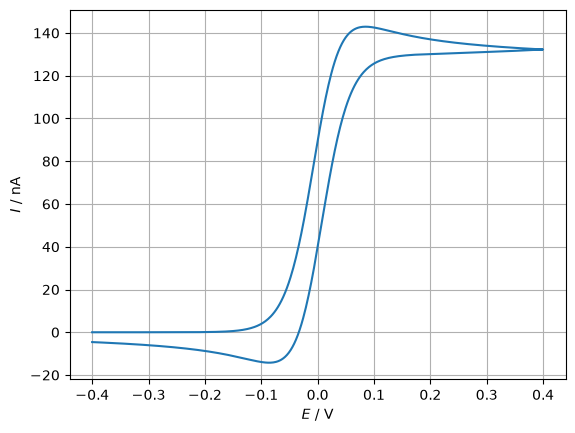

In [2]:
plt.figure()
plt.plot(sim.potential, sim.current*1e9)
plt.xlabel("$E$ / V")
plt.ylabel("$I$ / nA")
plt.grid()
plt.show()

In [3]:
sr = np.array([1e-3, 1e-2, 1e-1]) # V/s
sim = []
for s in sr:

    # Define CV
    cv = CyclicVoltammetry(
        E_start = -0.4,
        E_vertex1 = 0.4,
        E_vertex2 = -0.4,
        scan_rate = s
    )

    # Run simulation
    sim.append(simulate(
        technique = cv,
        mechanism = [ox, red],
        geometry = geometry
    )
)

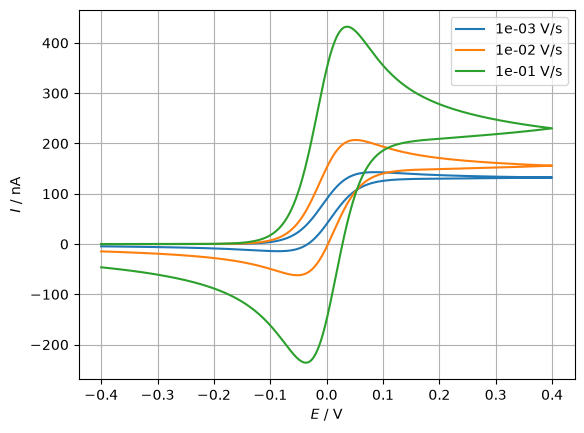

In [4]:
plt.figure()
for s in range(len(sr)):
    plt.plot(sim[s].potential, sim[s].current*1e9, label=f"{sr[s]:.0e} V/s")
plt.xlabel("$E$ / V")
plt.ylabel("$I$ / nA")
plt.grid()
plt.legend()
plt.show()